<a href="https://colab.research.google.com/github/LuisTT0903/Processamento-de-Sinais1/blob/main/Pratica7Quest%C3%A3o2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Parâmetros dos blocos da cascata
Bloco 1 (passa-altas): polos em f = 6353.6 Hz, r = 0.8481
Bloco 2 (passa-baixas): polos em f = 7797.0 Hz, r = 0.8907
H1(z) = (0.12122 z^2 -0.24245 z +0.12122) / (z^2 +0.69974 z +0.71920)
H2(z) = (0.43514 z^2 +0.87028 z +0.43514) / (z^2 +1.37154 z +0.79338)
H(z) = H1(z) H2(z)
b = [ 0.052749  0.       -0.105499  0.        0.052749]
a = [1.       2.071284 2.472305 1.541571 0.570598]
polos = [-0.6858+0.5684j -0.6858-0.5684j -0.3499+0.7725j -0.3499-0.7725j]  |p| = [0.8907 0.8907 0.8481 0.8481]
zeros = [-1.+0.j -1.-0.j  1.+0.j  1.+0.j]
Estável: True

Passa-faixa da questão 1 com mesma banda (2000 Hz): f0 = 7000 Hz, r = 0.7169

Comparação
                              Cascata (4a ordem)   Bloco Q1 (2a ordem)
Bordas -3 dB [Hz]                  [5989. 8000.]         [5776. 7776.]
Ganho máx em 6-8 kHz [dB]                   0.73                  0.06
Ganho mín em 6-8 kHz [dB]                  -2.99                 -4.38
Ondulação 6,3-7,7 kHz [dB]                 

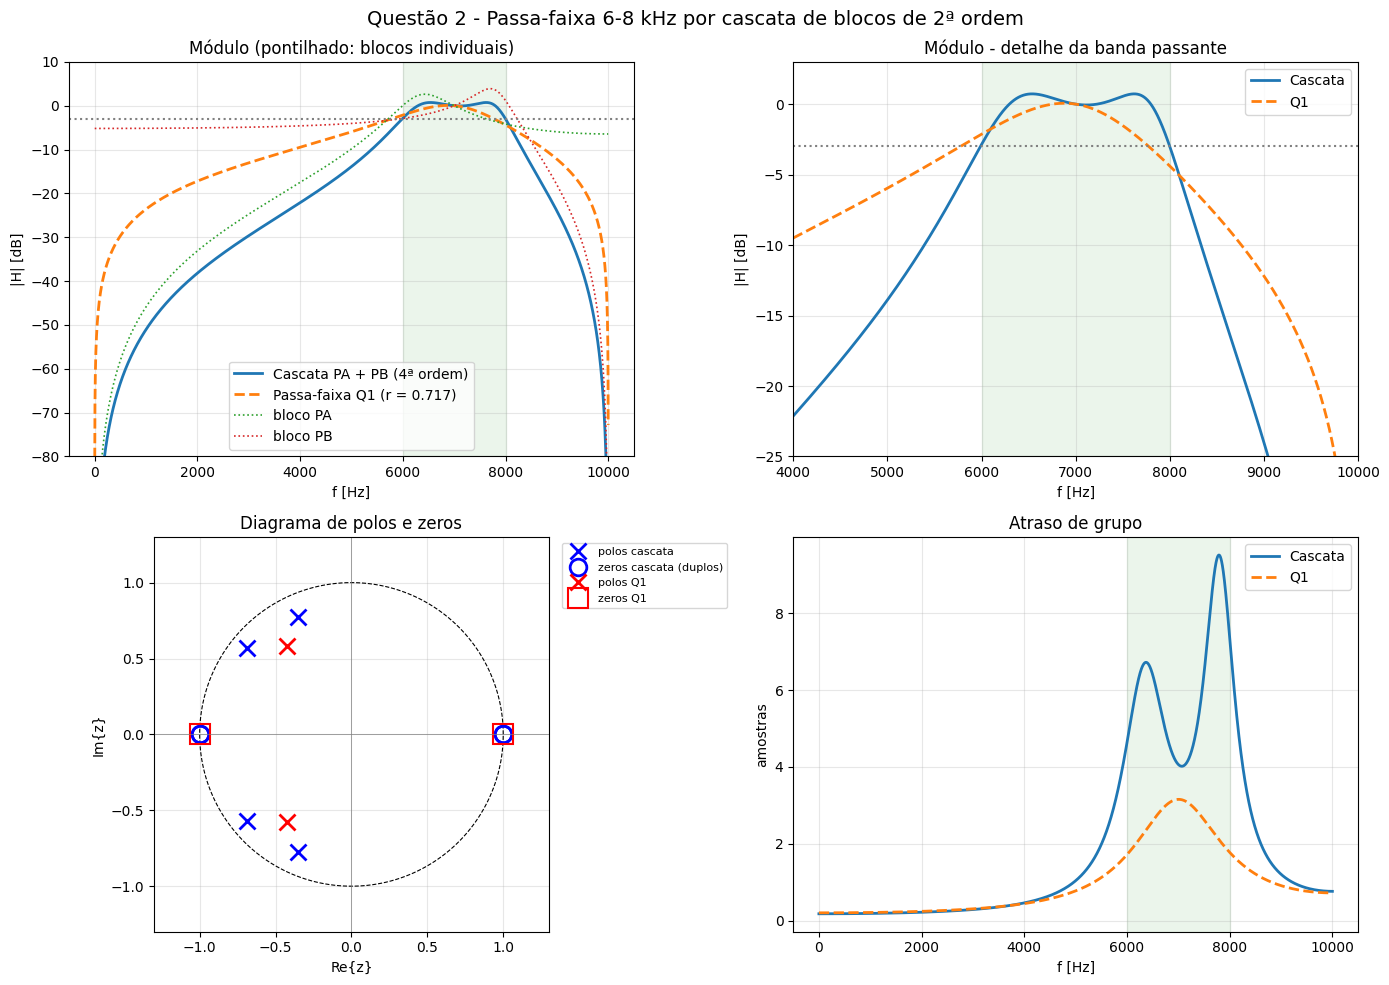

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, optimize

fs = 20000
fc1, fc2 = 6000, 8000
f0 = 7000
f = np.linspace(1, fs / 2 - 1, 4000)
zf = np.exp(2j * np.pi * f / fs)


def bloco(tipo, fp, r, f_norm):
    th = 2 * np.pi * fp / fs
    a = np.array([1.0, -2 * r * np.cos(th), r ** 2])
    if tipo == "pb":
        b = np.array([1.0, 2.0, 1.0])
    elif tipo == "pa":
        b = np.array([1.0, -2.0, 1.0])
    elif tipo == "pf":
        b = np.array([1.0, 0.0, -1.0])
    z0 = np.exp(2j * np.pi * f_norm / fs)
    g = abs(np.polyval(a, z0) / np.polyval(b, z0))
    return g * b, a


def cascata(x):
    fpa, rpa, fpb, rpb = x
    return [bloco("pa", fpa, rpa, f0), bloco("pb", fpb, rpb, f0)]


def resposta(blocos):
    H = np.ones_like(zf)
    for b, a in blocos:
        H = H * np.polyval(b, zf) / np.polyval(a, zf)
    return H


def db(H):
    return 20 * np.log10(np.abs(H) + 1e-12)


def valor(d, fe):
    return np.interp(fe, f, d)


def custo(x):
    if not (0 < x[1] < 0.995 and 0 < x[3] < 0.995 and 100 < x[0] < 9900 and 100 < x[2] < 9900):
        return 1e6
    d = db(resposta(cascata(x)))
    banda = (f >= fc1 + 200) & (f <= fc2 - 200)
    return 10 * ((valor(d, fc1) + 3) ** 2 + (valor(d, fc2) + 3) ** 2) + 5 * np.max(np.abs(d[banda])) ** 2


x0 = [6300, 0.85, 7800, 0.85]
res = optimize.minimize(custo, x0, method="Nelder-Mead", options={"maxiter": 40000, "maxfev": 40000, "xatol": 1e-7, "fatol": 1e-11})
res = optimize.minimize(custo, res.x, method="Nelder-Mead", options={"maxiter": 40000, "maxfev": 40000, "xatol": 1e-7, "fatol": 1e-11})
xo = res.x
blocos = cascata(xo)
b_tot = np.convolve(blocos[0][0], blocos[1][0])
a_tot = np.convolve(blocos[0][1], blocos[1][1])

print("Parâmetros dos blocos da cascata")
print(f"Bloco 1 (passa-altas): polos em f = {xo[0]:.1f} Hz, r = {xo[1]:.4f}")
print(f"Bloco 2 (passa-baixas): polos em f = {xo[2]:.1f} Hz, r = {xo[3]:.4f}")
for i, (b, a) in enumerate(blocos, 1):
    print(f"H{i}(z) = ({b[0]:.5f} z^2 {b[1]:+.5f} z {b[2]:+.5f}) / (z^2 {a[1]:+.5f} z {a[2]:+.5f})")
print("H(z) = H1(z) H2(z)")
print("b =", np.round(b_tot, 6))
print("a =", np.round(a_tot, 6))

z_tot, p_tot, k_tot = signal.tf2zpk(b_tot, a_tot)
print("polos =", np.round(p_tot, 4), " |p| =", np.round(np.abs(p_tot), 4))
print("zeros =", np.round(z_tot, 4))
print("Estável:", np.all(np.abs(p_tot) < 1))


def r_para_banda(bw):
    def g(r):
        b, a = bloco("pf", f0, r, f0)
        d = db(np.polyval(b, zf) / np.polyval(a, zf))
        c = np.where(np.diff((d >= -3).astype(int)) != 0)[0]
        return (f[c[-1]] - f[c[0]]) - bw
    return optimize.brentq(g, 0.3, 0.98)


r1 = r_para_banda(fc2 - fc1)
b_q1, a_q1 = bloco("pf", f0, r1, f0)
print(f"\nPassa-faixa da questão 1 com mesma banda (2000 Hz): f0 = {f0} Hz, r = {r1:.4f}")

H_c = resposta(blocos)
H_1 = np.polyval(b_q1, zf) / np.polyval(a_q1, zf)
d_c, d_1 = db(H_c), db(H_1)


def bordas(d):
    c = np.where(np.diff((d >= -3).astype(int)) != 0)[0]
    return [np.interp(-3, [d[i], d[i + 1]] if d[i] < d[i + 1] else [d[i + 1], d[i]], [f[i], f[i + 1]] if d[i] < d[i + 1] else [f[i + 1], f[i]]) for i in c]


banda = (f >= fc1) & (f <= fc2)
print("\nComparação")
print(f"{'':28}{'Cascata (4a ordem)':>20}{'Bloco Q1 (2a ordem)':>22}")
print(f"{'Bordas -3 dB [Hz]':28}{str(np.round(bordas(d_c), 0)):>20}{str(np.round(bordas(d_1), 0)):>22}")
print(f"{'Ganho máx em 6-8 kHz [dB]':28}{d_c[banda].max():>20.2f}{d_1[banda].max():>22.2f}")
print(f"{'Ganho mín em 6-8 kHz [dB]':28}{d_c[banda].min():>20.2f}{d_1[banda].min():>22.2f}")
interior = (f >= 6300) & (f <= 7700)
print(f"{'Ondulação 6,3-7,7 kHz [dB]':28}{np.ptp(d_c[interior]):>20.2f}{np.ptp(d_1[interior]):>22.2f}")
for fe in [2000, 4000, 5000, 9000, 9900]:
    print(f"{'Ganho em ' + str(fe) + ' Hz [dB]':28}{valor(d_c, fe):>20.2f}{valor(d_1, fe):>22.2f}")
for nivel in [-20, -40]:
    def largura(d):
        c = np.where(np.diff((d >= nivel).astype(int)) != 0)[0]
        return f[c[-1]] - f[c[0]] if len(c) >= 2 else np.nan
    print(f"{'Largura a ' + str(nivel) + ' dB [Hz]':28}{largura(d_c):>20.0f}{largura(d_1):>22.0f}")
fat = lambda d: (lambda c: (f[c[-1]] - f[c[0]]))(np.where(np.diff((d >= -20).astype(int)) != 0)[0]) / (lambda c: (f[c[-1]] - f[c[0]]))(np.where(np.diff((d >= -3).astype(int)) != 0)[0])
print(f"{'Fator de forma (-20/-3)':28}{fat(d_c):>20.2f}{fat(d_1):>22.2f}")

gd_c = -np.gradient(np.unwrap(np.angle(H_c)), 2 * np.pi * f / fs)
gd_1 = -np.gradient(np.unwrap(np.angle(H_1)), 2 * np.pi * f / fs)
print(f"{'Atraso de grupo em 7 kHz':28}{valor(gd_c, f0):>20.2f}{valor(gd_1, f0):>22.2f}")
print(f"{'Atraso de grupo máx 6-8 kHz':28}{gd_c[banda].max():>20.2f}{gd_1[banda].max():>22.2f}")

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0, 0].plot(f, d_c, lw=2, label="Cascata PA + PB (4ª ordem)")
ax[0, 0].plot(f, d_1, "--", lw=2, label=f"Passa-faixa Q1 (r = {r1:.3f})")
for (b, a), nome in zip(blocos, ["bloco PA", "bloco PB"]):
    ax[0, 0].plot(f, db(np.polyval(b, zf) / np.polyval(a, zf)), ":", lw=1.2, label=nome)
ax[0, 0].axvspan(fc1, fc2, color="green", alpha=0.08)
ax[0, 0].axhline(-3, color="gray", ls=":")
ax[0, 0].set_ylim(-80, 10)
ax[0, 0].set_title("Módulo (pontilhado: blocos individuais)")
ax[0, 0].set_xlabel("f [Hz]")
ax[0, 0].set_ylabel("|H| [dB]")
ax[0, 0].legend()

ax[0, 1].plot(f, d_c, lw=2, label="Cascata")
ax[0, 1].plot(f, d_1, "--", lw=2, label="Q1")
ax[0, 1].axvspan(fc1, fc2, color="green", alpha=0.08)
ax[0, 1].axhline(-3, color="gray", ls=":")
ax[0, 1].set_xlim(4000, 10000)
ax[0, 1].set_ylim(-25, 3)
ax[0, 1].set_title("Módulo - detalhe da banda passante")
ax[0, 1].set_xlabel("f [Hz]")
ax[0, 1].set_ylabel("|H| [dB]")
ax[0, 1].legend()

t = np.linspace(0, 2 * np.pi, 400)
z1, p1, _ = signal.tf2zpk(b_q1, a_q1)
ax[1, 0].plot(np.cos(t), np.sin(t), "k--", lw=0.8)
ax[1, 0].plot(p_tot.real, p_tot.imag, "bx", ms=11, mew=2, label="polos cascata")
ax[1, 0].plot(z_tot.real, z_tot.imag, "bo", mfc="none", ms=12, mew=2, label="zeros cascata (duplos)")
ax[1, 0].plot(p1.real, p1.imag, "rx", ms=11, mew=2, label="polos Q1")
ax[1, 0].plot(z1.real, z1.imag, "rs", mfc="none", ms=14, mew=1.5, label="zeros Q1")
ax[1, 0].set_aspect("equal")
ax[1, 0].set_xlim(-1.3, 1.3)
ax[1, 0].set_ylim(-1.3, 1.3)
ax[1, 0].axhline(0, color="gray", lw=0.5)
ax[1, 0].axvline(0, color="gray", lw=0.5)
ax[1, 0].set_title("Diagrama de polos e zeros")
ax[1, 0].set_xlabel("Re{z}")
ax[1, 0].set_ylabel("Im{z}")
ax[1, 0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))

ax[1, 1].plot(f, gd_c, lw=2, label="Cascata")
ax[1, 1].plot(f, gd_1, "--", lw=2, label="Q1")
ax[1, 1].axvspan(fc1, fc2, color="green", alpha=0.08)
ax[1, 1].set_title("Atraso de grupo")
ax[1, 1].set_xlabel("f [Hz]")
ax[1, 1].set_ylabel("amostras")
ax[1, 1].legend()
for a_ in ax.flat:
    a_.grid(alpha=0.3)
fig.suptitle("Questão 2 - Passa-faixa 6-8 kHz por cascata de blocos de 2ª ordem", fontsize=14)
fig.tight_layout()
plt.savefig("questao2.png", dpi=110)
plt.show()

O passa-faixas foi feito em cascata: um bloco passa-altas, com polos em 6354 Hz e r = 0,848, define a borda inferior, e um bloco passa-baixas, com polos em 7797 Hz e r = 0,891, define a borda superior. Esses parâmetros foram ajustados numericamente. O filtro resultante, de 4ª ordem, tem bordas de -3 dB em 5989 e 8000 Hz e ondulação de 0,79 dB na banda. Os zeros são duplos em z = 1 e z = -1, e os quatro polos ficam dentro do círculo unitário, então o filtro é estável.

Para a comparação usei o passa-faixas da questão 1 com a mesma largura de banda (r = 0,717). A cascata é muito mais seletiva. Em 4 kHz ela atenua 22,1 dB, contra 9,5 dB do bloco único, e em 9 kHz atenua 24,0 dB, contra 12,2 dB. O fator de forma (largura a -20 dB sobre largura a -3 dB) cai de 4,04 para 2,25, e a banda passante é mais plana do que o formato de sino do bloco único. Em troca, a cascata tem o dobro de operações por amostra e um atraso de grupo maior perto das bordas: 9,5 amostras, contra 3,2.